In [1]:

import torch
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("Enable GPU in Colab before training.")


Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
%pip install --no-deps --force-reinstall \
    "pandas==2.2.3" \
    "pyarrow==23.0.1" \
    "python-dateutil==2.9.0.post0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 75.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 51.5 MB/s  0:00:00
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 2.9.0.post0
    Uninstalling python-dateutil-2.9.0.post0:
      Successfully uninstalled python-dateutil-2.9.0.post0
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pandas]


In [3]:
%pip install --no-deps --force-reinstall "datasets==3.6.0"

  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5


In [4]:
import torch
import pandas as pd
import pyarrow
import dateutil
import datasets

print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("PyArrow:", pyarrow.__version__)
print("Dateutil:", dateutil.__version__)
print("Datasets:", datasets.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Pandas: 2.2.3
PyArrow: 23.0.1
Dateutil: 2.9.0.post0
Datasets: 3.6.0
CUDA: True
GPU: Tesla T4


In [5]:
%pip check

ipython 7.34.0 requires jedi, which is not installed.
datasets 3.6.0 has requirement dill<0.3.9,>=0.3.0, but you have dill 0.4.1.
datasets 3.6.0 has requirement fsspec[http]<=2025.3.0,>=2023.1.0, but you have fsspec 2025.12.0.
datasets 3.6.0 has requirement multiprocess<0.70.17, but you have multiprocess 0.70.19.


In [6]:

%pip -q install -U transformers datasets accelerate scikit-learn pandas matplotlib seaborn safetensors


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [7]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [8]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

matches = list(drive_root.rglob(
    "final_week4_model_comparison.csv"
))

for i, path in enumerate(matches[:20]):
    print(i, path)

assert matches, (
    "Week 4 comparison not found. "
    "Check Drive mount and folder names."
)

week4_results = matches[0].parent
project_root = week4_results.parent.parent

print("Project root:", project_root)
print("Week 4 results:", week4_results)


0 /content/drive/MyDrive/TrustFact/results/week4/distilbert/final_week4_model_comparison.csv
Project root: /content/drive/MyDrive/TrustFact/results
Week 4 results: /content/drive/MyDrive/TrustFact/results/week4/distilbert


In [9]:
import os
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

print("Random seed set to:", SEED)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Random seed set to: 42
PyTorch version: 2.14.1+cu130
CUDA available: True
Using device: cuda


In [10]:

import json
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

week5_dir = project_root / "results" / "week5"

folders = {
    "bert": week5_dir / "bert",
    "roberta": week5_dir / "roberta",
    "comparison": week5_dir / "comparison",
    "figures": week5_dir / "figures",
    "logs": week5_dir / "logs"
}

for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)

print("Week 5 directories created:")
for name, folder in folders.items():
    print(name, folder)


Week 5 directories created:
bert /content/drive/MyDrive/TrustFact/results/results/week5/bert
roberta /content/drive/MyDrive/TrustFact/results/results/week5/roberta
comparison /content/drive/MyDrive/TrustFact/results/results/week5/comparison
figures /content/drive/MyDrive/TrustFact/results/results/week5/figures
logs /content/drive/MyDrive/TrustFact/results/results/week5/logs


In [11]:
from pathlib import Path
import pandas as pd

# Correct TrustFact dataset path
data_root = Path("/content/drive/MyDrive/TrustFact/data/raw/liar")

train_path = data_root / "train.tsv"
valid_path = data_root / "valid.tsv"
test_path = data_root / "test.tsv"

# Verify files
for path in [train_path, valid_path, test_path]:
    print(f"{path.name}: {'FOUND' if path.exists() else 'MISSING'}")

# Stop only if a required file is missing
assert all(p.exists() for p in [train_path, valid_path, test_path]), \
    "One or more LIAR dataset files are missing."

train.tsv: FOUND
valid.tsv: FOUND
test.tsv: FOUND


In [12]:
PROJECT_ROOT = Path("/content/drive/MyDrive/TrustFact")

DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "liar"
RESULTS_ROOT = PROJECT_ROOT / "results" / "week5"

RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", DATA_ROOT)
print("Results directory:", RESULTS_ROOT)

Dataset directory: /content/drive/MyDrive/TrustFact/data/raw/liar
Results directory: /content/drive/MyDrive/TrustFact/results/week5


In [13]:
from pathlib import Path
import pandas as pd

# Set the correct dataset location
data_root = Path("/content/drive/MyDrive/TrustFact/data/raw/liar")

# Define column names
columns = [
    "id", "label", "statement", "subject",
    "speaker", "speaker_job", "state",
    "party", "barely_true_count", "false_count",
    "half_true_count", "mostly_true_count",
    "pants_fire_count", "context"
]

# Verify dataset files exist
for name in ["train.tsv", "valid.tsv", "test.tsv"]:
    path = data_root / name
    print(f"{name}: {path.exists()}")

# Load LIAR dataset
train_df = pd.read_csv(
    data_root / "train.tsv",
    sep="\t", header=None, names=columns
)

valid_df = pd.read_csv(
    data_root / "valid.tsv",
    sep="\t", header=None, names=columns
)

test_df = pd.read_csv(
    data_root / "test.tsv",
    sep="\t", header=None, names=columns
)

print("\nSUCCESS! Dataset loaded.")
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))

train.tsv: True
valid.tsv: True
test.tsv: True

SUCCESS! Dataset loaded.
Train: 10240
Validation: 1284
Test: 1267


In [14]:
from pathlib import Path
import pandas as pd

# ==========================================
# STEP 1: Set correct dataset path
# ==========================================

data_root = Path("/content/drive/MyDrive/TrustFact/data/raw/liar")

assert data_root.exists(), f"Dataset folder not found: {data_root}"

# ==========================================
# STEP 2: Define LIAR dataset columns
# ==========================================

columns = [
    "id", "label", "statement", "subject",
    "speaker", "speaker_job", "state",
    "party", "barely_true_count",
    "false_count", "half_true_count",
    "mostly_true_count", "pants_fire_count",
    "context"
]

# ==========================================
# STEP 3: Load training and validation data
# ==========================================

train_df = pd.read_csv(
    data_root / "train.tsv",
    sep="\t",
    header=None,
    names=columns
)

val_df = pd.read_csv(
    data_root / "valid.tsv",
    sep="\t",
    header=None,
    names=columns
)

# ==========================================
# STEP 4: Define six classification labels
# ==========================================

labels = [
    "pants-fire",
    "false",
    "barely-true",
    "half-true",
    "mostly-true",
    "true"
]

label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

# ==========================================
# STEP 5: Convert labels to numeric IDs
# ==========================================

for df in [train_df, val_df]:
    df["label_id"] = df["label"].map(label2id)

# ==========================================
# STEP 6: Validate datasets
# ==========================================

assert len(train_df) == 10240, "Incorrect training dataset size"
assert len(val_df) == 1284, "Incorrect validation dataset size"

assert train_df["label_id"].notna().all()
assert val_df["label_id"].notna().all()

assert train_df["statement"].notna().all()
assert val_df["statement"].notna().all()

# ==========================================
# STEP 7: Display results
# ==========================================

print("Dataset loaded successfully!")
print("Dataset location:", data_root)

print("\nTraining:", train_df.shape)
print("Validation:", val_df.shape)

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

print("\nLabel mappings:")
print(label2id)

Dataset loaded successfully!
Dataset location: /content/drive/MyDrive/TrustFact/data/raw/liar

Training: (10240, 15)
Validation: (1284, 15)

Training label distribution:
label
half-true      2114
false          1995
mostly-true    1962
true           1676
barely-true    1654
pants-fire      839
Name: count, dtype: int64

Label mappings:
{'pants-fire': 0, 'false': 1, 'barely-true': 2, 'half-true': 3, 'mostly-true': 4, 'true': 5}


In [15]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/TrustFact")
WEEK5_ROOT = PROJECT_ROOT / "results" / "week5"
WEEK5_ROOT.mkdir(parents=True, exist_ok=True)

# Find the saved Week 4 DistilBERT model
model_files = list(
    (PROJECT_ROOT / "results" / "week4").rglob("model.safetensors")
)

print("Saved model files found:")

for file in model_files:
    print(file.parent)

assert model_files, "No saved Week 4 model found."

# Prefer the best_model directory
best_models = [
    p.parent for p in model_files
    if p.parent.name == "best_model"
]

assert best_models, "Week 4 best_model directory not found."

MODEL_PATH = best_models[0]

print("\nModel selected:", MODEL_PATH)

Saved model files found:
/content/drive/MyDrive/TrustFact/results/week4/distilbert/best_model
/content/drive/MyDrive/TrustFact/results/week4/distilbert/weighted_checkpoints/checkpoint-640
/content/drive/MyDrive/TrustFact/results/week4/distilbert/weighted_checkpoints/checkpoint-1280
/content/drive/MyDrive/TrustFact/results/week4/distilbert/checkpoints/checkpoint-1280
/content/drive/MyDrive/TrustFact/results/week4/distilbert/checkpoints/checkpoint-1920

Model selected: /content/drive/MyDrive/TrustFact/results/week4/distilbert/best_model


In [16]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

tokenizer = AutoTokenizer.from_pretrained(str(MODEL_PATH))

model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_PATH),
    num_labels=6,
    ignore_mismatched_sizes=False
)

model.config.label2id = label2id
model.config.id2label = id2label

print("Model loaded successfully!")
print("Number of labels:", model.config.num_labels)
print("GPU available:", torch.cuda.is_available())

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully!
Number of labels: 6
GPU available: True


In [17]:
MAX_LENGTH = 128

train_encodings = tokenizer(
    train_df["statement"].astype(str).tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

val_encodings = tokenizer(
    val_df["statement"].astype(str).tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

print("Training statements:", len(train_encodings["input_ids"]))
print("Validation statements:", len(val_encodings["input_ids"]))
print("Tokenization successful!")

Training statements: 10240
Validation statements: 1284
Tokenization successful!


In [18]:
class LIARDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }
        item["labels"] = torch.tensor(
            self.labels[idx], dtype=torch.long
        )
        return item

    def __len__(self):
        return len(self.labels)


train_dataset = LIARDataset(
    train_encodings,
    train_df["label_id"].astype(int).tolist()
)

val_dataset = LIARDataset(
    val_encodings,
    val_df["label_id"].astype(int).tolist()
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 10240
Validation dataset: 1284


In [19]:
import inspect
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import TrainingArguments, Trainer

def compute_metrics(eval_pred):
    logits, targets = eval_pred

    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets,
            predictions,
            average="macro",
            zero_division=0
        )
    }

training_kwargs = dict(
    output_dir=str(WEEK5_ROOT / "checkpoints"),
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42
)

# Support older Transformers versions
params = inspect.signature(TrainingArguments).parameters

if "eval_strategy" not in params:
    training_kwargs["evaluation_strategy"] = \
        training_kwargs.pop("eval_strategy")

training_args = TrainingArguments(**training_kwargs)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("Week 5 trainer configured successfully!")

Week 5 trainer configured successfully!


In [20]:
assert torch.cuda.is_available(), \
    "Enable T4 GPU before starting training."

train_result = trainer.train()

print("Week 5 training completed!")
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,2.828095,1.788175,0.253894,0.244527
2,2.374807,1.893316,0.262461,0.257304


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Week 5 training completed!
{'train_runtime': 191.8645, 'train_samples_per_second': 106.742, 'train_steps_per_second': 6.671, 'total_flos': 678281462415360.0, 'train_loss': 2.6386475443840025, 'epoch': 2.0}


In [21]:
results = trainer.evaluate()

print("\nWeek 5 Validation Results")
print("==========================")
print("Accuracy:", round(results["eval_accuracy"], 4))
print("Macro-F1:", round(results["eval_macro_f1"], 4))

baseline_f1 = 0.2619
pilot_f1 = 0.2742

print("\nComparison:")
print("Week 4 Logistic Regression:", baseline_f1)
print("Week 3 DistilBERT pilot:", pilot_f1)
print("Week 5 DistilBERT:", round(results["eval_macro_f1"], 4))

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
2.374807,1.893316,2,0.262461,0.257304



Week 5 Validation Results
Accuracy: 0.2625
Macro-F1: 0.2573

Comparison:
Week 4 Logistic Regression: 0.2619
Week 3 DistilBERT pilot: 0.2742
Week 5 DistilBERT: 0.2573


In [22]:
import json

final_model_path = WEEK5_ROOT / "distilbert" / "best_model"
final_model_path.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(final_model_path))
tokenizer.save_pretrained(str(final_model_path))

with open(WEEK5_ROOT / "validation_metrics.json", "w") as f:
    json.dump(results, f, indent=4)

print("Week 5 model saved:", final_model_path)
print("Validation metrics saved!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Week 5 model saved: /content/drive/MyDrive/TrustFact/results/week5/distilbert/best_model
Validation metrics saved!


In [23]:
import json
from pathlib import Path

metrics_path = Path(
    "/content/drive/MyDrive/TrustFact/results/week5/validation_metrics.json"
)

with open(metrics_path, "r") as f:
    metrics = json.load(f)

print("TRUSTFACT WEEK 5 RESULTS")
print("========================")

print("Validation Accuracy:",
      round(metrics["eval_accuracy"], 4))

print("Validation Macro-F1:",
      round(metrics["eval_macro_f1"], 4))

print("\nPREVIOUS BENCHMARKS")
print("Logistic Regression: 0.2619")
print("DistilBERT Pilot:    0.2742")

print("\nWeek 5 Improvement over Pilot:",
      round(metrics["eval_macro_f1"] - 0.2742, 4))

TRUSTFACT WEEK 5 RESULTS
Validation Accuracy: 0.2625
Validation Macro-F1: 0.2573

PREVIOUS BENCHMARKS
Logistic Regression: 0.2619
DistilBERT Pilot:    0.2742

Week 5 Improvement over Pilot: -0.0169


In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

pred_output = trainer.predict(val_dataset)

predictions = np.argmax(pred_output.predictions, axis=1)

report = classification_report(
    val_df["label_id"].astype(int),
    predictions,
    target_names=labels,
    zero_division=0
)

print(report)

# Save report
report_path = WEEK5_ROOT / "classification_report.txt"

with open(report_path, "w") as f:
    f.write(report)

# Save confusion matrix
cm = confusion_matrix(
    val_df["label_id"].astype(int),
    predictions,
    labels=list(range(6))
)

pd.DataFrame(
    cm,
    index=labels,
    columns=labels
).to_csv(WEEK5_ROOT / "confusion_matrix.csv")

print("Classification report and confusion matrix saved!")

              precision    recall  f1-score   support

  pants-fire       0.27      0.16      0.20       116
       false       0.27      0.29      0.28       263
 barely-true       0.25      0.23      0.24       237
   half-true       0.23      0.25      0.24       248
 mostly-true       0.32      0.26      0.29       251
        true       0.25      0.35      0.29       169

    accuracy                           0.26      1284
   macro avg       0.26      0.26      0.26      1284
weighted avg       0.27      0.26      0.26      1284

Classification report and confusion matrix saved!


In [25]:
for path in sorted(WEEK5_ROOT.rglob("*")):
    if path.is_file() and "checkpoint-" not in str(path):
        print(path.relative_to(WEEK5_ROOT))

classification_report.txt
confusion_matrix.csv
distilbert/best_model/config.json
distilbert/best_model/model.safetensors
distilbert/best_model/tokenizer.json
distilbert/best_model/tokenizer_config.json
distilbert/best_model/training_args.bin
experiments/low_learning_rate/best_model/config.json
experiments/low_learning_rate/best_model/tokenizer.json
experiments/low_learning_rate/best_model/tokenizer_config.json
experiments/low_learning_rate/best_model/training_args.bin
experiments/low_learning_rate/metrics.json
validation_metrics.json


In [26]:
import json
from pathlib import Path

WEEK5_ROOT = Path(
    "/content/drive/MyDrive/TrustFact/results/week5"
)

with open(WEEK5_ROOT / "validation_metrics.json") as f:
    results = json.load(f)

accuracy = results["eval_accuracy"]
macro_f1 = results["eval_macro_f1"]

print("TRUSTFACT WEEK 5 PERFORMANCE")
print("=" * 40)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Macro-F1: {macro_f1:.4f}")

print("\nComparison with previous models:")
print("Logistic Regression: 0.2619")
print("DistilBERT Pilot:    0.2742")
print(f"Week 5 DistilBERT:  {macro_f1:.4f}")

print("\nImprovement over pilot:")
print(f"{macro_f1 - 0.2742:+.4f}")

TRUSTFACT WEEK 5 PERFORMANCE
Validation Accuracy: 0.2625
Validation Macro-F1: 0.2573

Comparison with previous models:
Logistic Regression: 0.2619
DistilBERT Pilot:    0.2742
Week 5 DistilBERT:  0.2573

Improvement over pilot:
-0.0169


In [27]:
report_path = WEEK5_ROOT / "classification_report.txt"

with open(report_path, "r") as f:
    print(f.read())

              precision    recall  f1-score   support

  pants-fire       0.27      0.16      0.20       116
       false       0.27      0.29      0.28       263
 barely-true       0.25      0.23      0.24       237
   half-true       0.23      0.25      0.24       248
 mostly-true       0.32      0.26      0.29       251
        true       0.25      0.35      0.29       169

    accuracy                           0.26      1284
   macro avg       0.26      0.26      0.26      1284
weighted avg       0.27      0.26      0.26      1284



In [28]:
import matplotlib
matplotlib.use("Agg", force=True)

import matplotlib.pyplot as plt
plt.close("all")

print("Matplotlib reset successfully!")

Matplotlib reset successfully!


In [29]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

WEEK5_ROOT = Path(
    "/content/drive/MyDrive/TrustFact/results/week5"
)

# Load previously saved confusion matrix
cm_df = pd.read_csv(
    WEEK5_ROOT / "confusion_matrix.csv",
    index_col=0
)

print("Confusion matrix loaded!")
print(cm_df)

# Create figure
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm_df.values, cmap="Blues")

ax.set_xticks(np.arange(len(cm_df.columns)))
ax.set_yticks(np.arange(len(cm_df.index)))

ax.set_xticklabels(cm_df.columns, rotation=45, ha="right")
ax.set_yticklabels(cm_df.index)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("TrustFact Week 5 - DistilBERT Confusion Matrix")

# Add numbers to cells
for i in range(cm_df.shape[0]):
    for j in range(cm_df.shape[1]):
        ax.text(
            j, i,
            str(cm_df.iloc[i, j]),
            ha="center",
            va="center",
            color="white" if cm_df.iloc[i, j] > cm_df.values.max()/2 else "black"
        )

fig.colorbar(im, ax=ax)
fig.tight_layout()

# Save figure
output_path = WEEK5_ROOT / "confusion_matrix.png"

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)

print("\nConfusion matrix saved successfully!")
print("Location:", output_path)

Confusion matrix loaded!
             pants-fire  false  barely-true  half-true  mostly-true  true
pants-fire           19     42           21         17            5    12
false                23     77           63         44           27    29
barely-true           9     55           55         58           24    36
half-true             8     54           39         61           46    40
mostly-true           8     36           31         54           66    56
true                  3     18           14         35           40    59

Confusion matrix saved successfully!
Location: /content/drive/MyDrive/TrustFact/results/week5/confusion_matrix.png


In [30]:
image_path = WEEK5_ROOT / "confusion_matrix.png"

print("Image exists:", image_path.exists())

if image_path.exists():
    print("File size:", round(image_path.stat().st_size / 1024, 2), "KB")

Image exists: True
File size: 127.0 KB


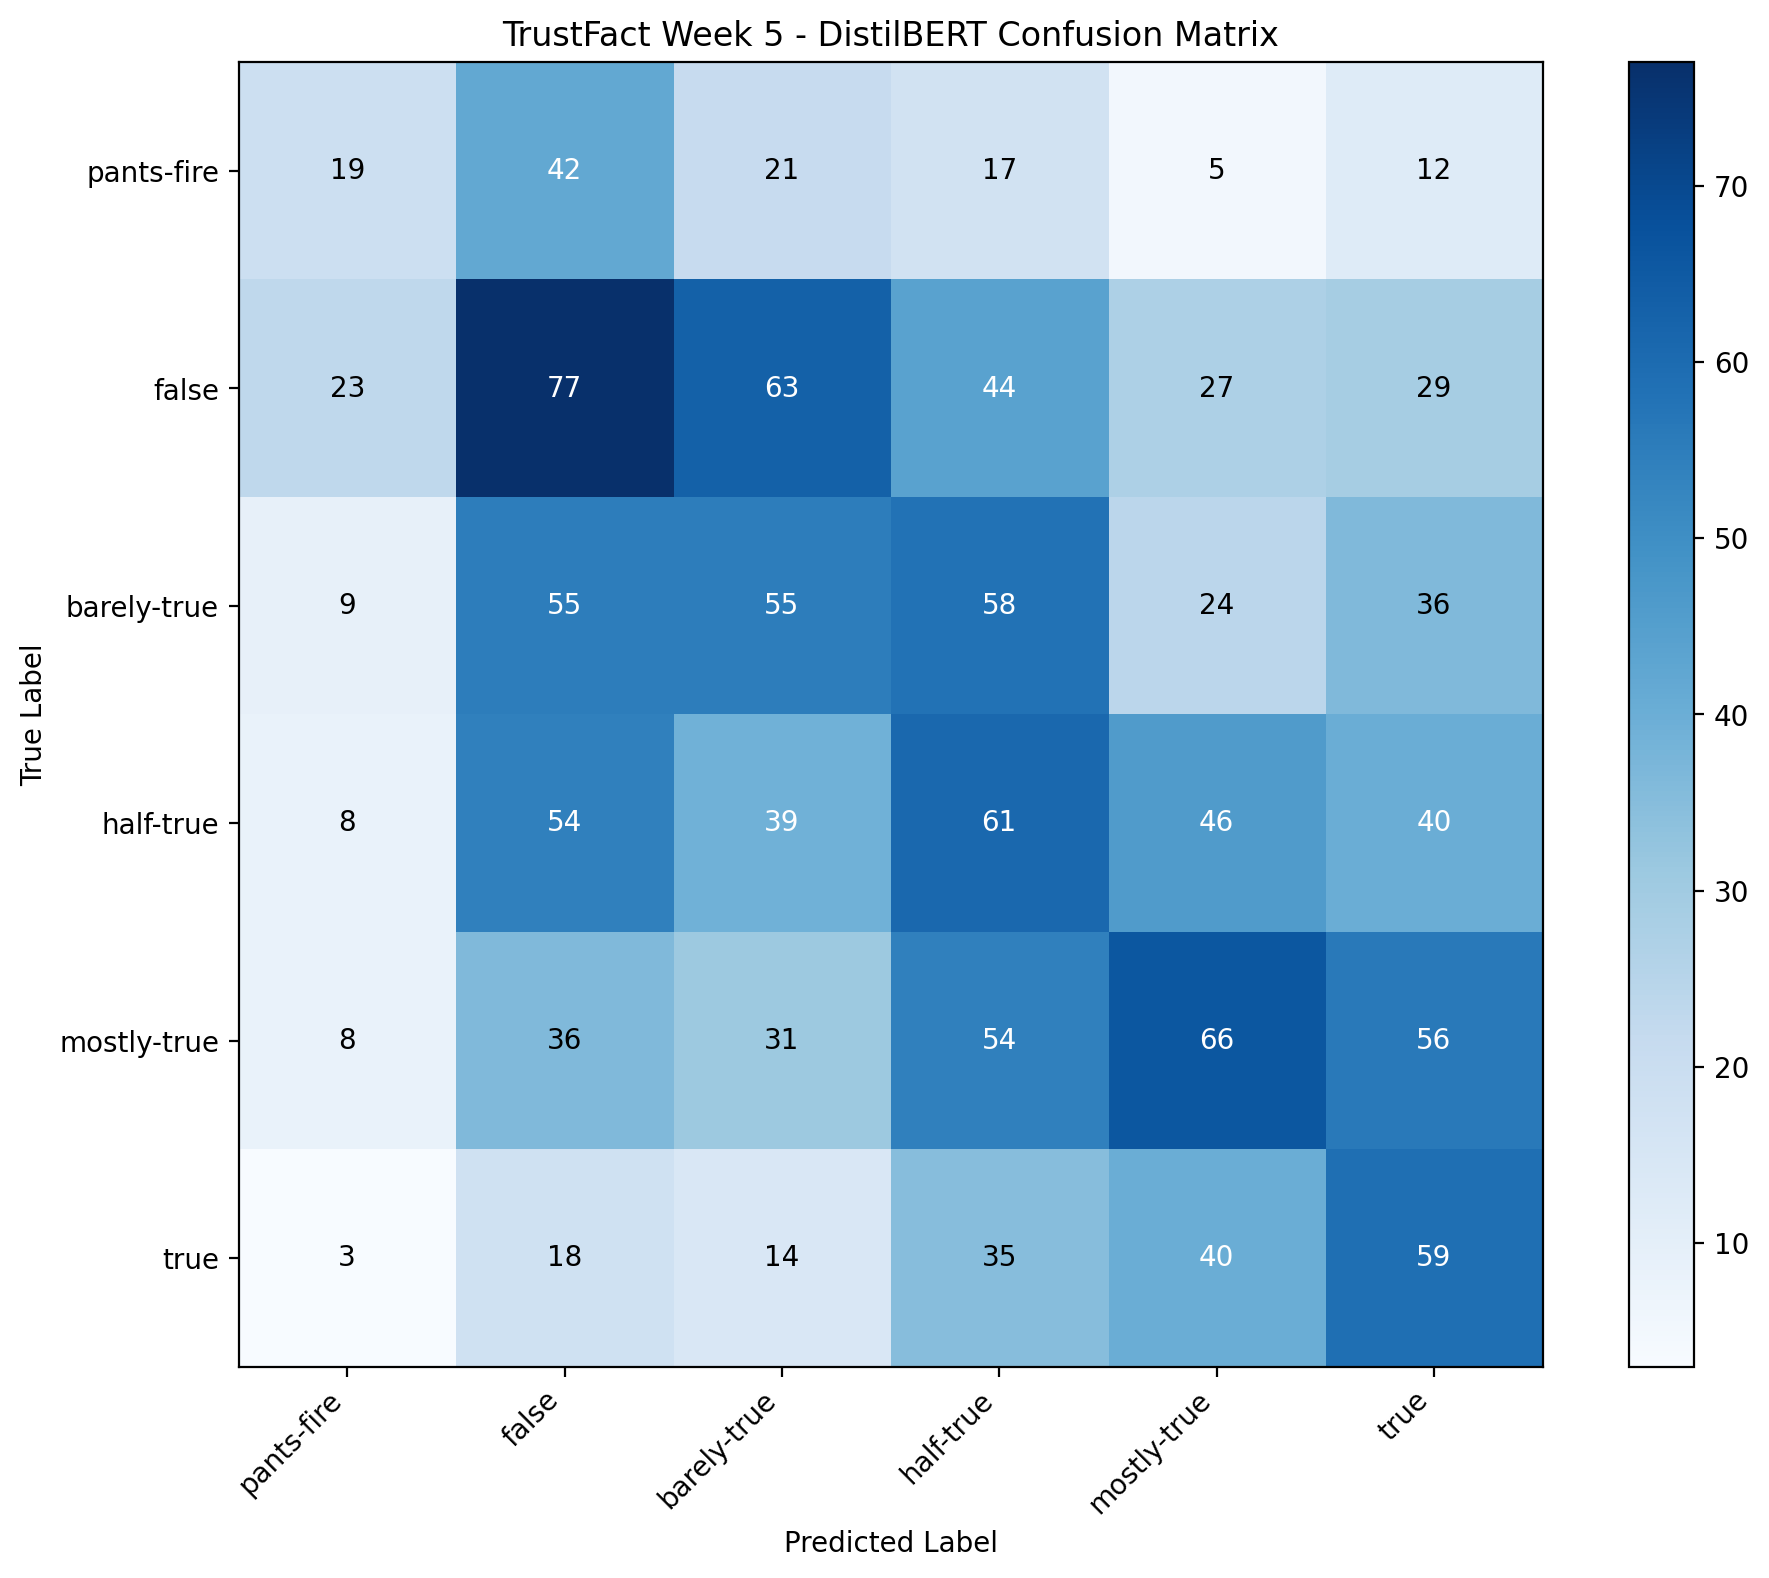

In [31]:
from IPython.display import display, Image

display(Image(filename=str(image_path)))

In [32]:
import json
from pathlib import Path

WEEK5_ROOT = Path(
    "/content/drive/MyDrive/TrustFact/results/week5"
)

with open(WEEK5_ROOT / "validation_metrics.json") as f:
    metrics = json.load(f)

print("=" * 45)
print("TRUSTFACT WEEK 5 PERFORMANCE SUMMARY")
print("=" * 45)

print(f"Validation Accuracy: {metrics['eval_accuracy']:.4f}")
print(f"Validation Macro-F1: {metrics['eval_macro_f1']:.4f}")

print("\nCLASSIFICATION REPORT")
print("-" * 45)

with open(WEEK5_ROOT / "classification_report.txt") as f:
    print(f.read())

print("\nBENCHMARK COMPARISON")
print("-" * 45)

print("Logistic Regression: 0.2619")
print("DistilBERT Pilot:    0.2742")
print(f"Week 5 DistilBERT:  {metrics['eval_macro_f1']:.4f}")

TRUSTFACT WEEK 5 PERFORMANCE SUMMARY
Validation Accuracy: 0.2625
Validation Macro-F1: 0.2573

CLASSIFICATION REPORT
---------------------------------------------
              precision    recall  f1-score   support

  pants-fire       0.27      0.16      0.20       116
       false       0.27      0.29      0.28       263
 barely-true       0.25      0.23      0.24       237
   half-true       0.23      0.25      0.24       248
 mostly-true       0.32      0.26      0.29       251
        true       0.25      0.35      0.29       169

    accuracy                           0.26      1284
   macro avg       0.26      0.26      0.26      1284
weighted avg       0.27      0.26      0.26      1284


BENCHMARK COMPARISON
---------------------------------------------
Logistic Regression: 0.2619
DistilBERT Pilot:    0.2742
Week 5 DistilBERT:  0.2573


In [33]:
import pandas as pd

history = pd.DataFrame(trainer.state.log_history)

cols = [
    col for col in [
        "epoch", "step", "loss", "eval_loss",
        "eval_accuracy", "eval_macro_f1"
    ]
    if col in history.columns
]

print(history[cols].dropna(how="all").to_string(index=False))

history.to_csv(
    WEEK5_ROOT / "training_history.csv",
    index=False
)

print("\nTraining history saved!")

  epoch  step     loss  eval_loss  eval_accuracy  eval_macro_f1
0.15625   100 3.002879        NaN            NaN            NaN
0.31250   200 2.928003        NaN            NaN            NaN
0.46875   300 2.869477        NaN            NaN            NaN
0.62500   400 2.889847        NaN            NaN            NaN
0.78125   500 2.881530        NaN            NaN            NaN
0.93750   600 2.828095        NaN            NaN            NaN
1.00000   640      NaN   1.788175       0.253894       0.244527
1.09375   700 2.597760        NaN            NaN            NaN
1.25000   800 2.460866        NaN            NaN            NaN
1.40625   900 2.341260        NaN            NaN            NaN
1.56250  1000 2.368221        NaN            NaN            NaN
1.71875  1100 2.275587        NaN            NaN            NaN
1.87500  1200 2.374807        NaN            NaN            NaN
2.00000  1280      NaN   1.893316       0.262461       0.257304
2.00000  1280      NaN        NaN       

In [34]:
import pandas as pd
from pathlib import Path

WEEK5_ROOT = Path(
    "/content/drive/MyDrive/TrustFact/results/week5"
)

history_path = WEEK5_ROOT / "training_history.csv"

if history_path.exists():
    history = pd.read_csv(history_path)
elif "trainer" in globals():
    history = pd.DataFrame(trainer.state.log_history)
    history.to_csv(history_path, index=False)
else:
    raise RuntimeError(
        "Training history not found. Check saved checkpoints."
    )

cols = [
    "epoch",
    "step",
    "loss",
    "eval_loss",
    "eval_accuracy",
    "eval_macro_f1"
]

available_cols = [c for c in cols if c in history.columns]

print("TRUSTFACT WEEK 5 TRAINING HISTORY")
print("=" * 45)
print(history[available_cols].dropna(
    how="all",
    subset=[c for c in available_cols if c != "step"]
).to_string(index=False))

TRUSTFACT WEEK 5 TRAINING HISTORY
  epoch  step     loss  eval_loss  eval_accuracy  eval_macro_f1
0.15625   100 3.002879        NaN            NaN            NaN
0.31250   200 2.928003        NaN            NaN            NaN
0.46875   300 2.869477        NaN            NaN            NaN
0.62500   400 2.889847        NaN            NaN            NaN
0.78125   500 2.881530        NaN            NaN            NaN
0.93750   600 2.828095        NaN            NaN            NaN
1.00000   640      NaN   1.788175       0.253894       0.244527
1.09375   700 2.597760        NaN            NaN            NaN
1.25000   800 2.460866        NaN            NaN            NaN
1.40625   900 2.341260        NaN            NaN            NaN
1.56250  1000 2.368221        NaN            NaN            NaN
1.71875  1100 2.275587        NaN            NaN            NaN
1.87500  1200 2.374807        NaN            NaN            NaN
2.00000  1280      NaN   1.893316       0.262461       0.257304
2.0000

In [35]:
import numpy as np
import pandas as pd

# Use the trained model to predict validation samples
pred_output = trainer.predict(val_dataset)

predictions = np.argmax(
    pred_output.predictions, axis=1
)

error_df = val_df[
    ["statement", "label", "label_id"]
].copy()

error_df["predicted_id"] = predictions
error_df["predicted_label"] = [
    id2label[int(i)] for i in predictions
]

error_df["correct"] = (
    error_df["label_id"] == error_df["predicted_id"]
)

misclassified = error_df[
    ~error_df["correct"]
].copy()

misclassified.to_csv(
    WEEK5_ROOT / "misclassified_statements.csv",
    index=False
)

print("Total validation statements:", len(error_df))
print("Correct predictions:", error_df["correct"].sum())
print("Incorrect predictions:", len(misclassified))

print("\nFirst 10 misclassified statements:")
print(
    misclassified[
        ["statement", "label", "predicted_label"]
    ].head(10).to_string(index=False)
)

Total validation statements: 1284
Correct predictions: 337
Incorrect predictions: 947

First 10 misclassified statements:
                                                                                                                                                                                                   statement       label predicted_label
                                                                                                                                                         We have less Americans working now than in the 70s. barely-true       half-true
                                                        When Obama was sworn into office, he DID NOT use the Holy Bible, but instead the Kuran (Their equivalency to our Bible, but very different beliefs).  pants-fire           false
Says Having organizations parading as being social welfare organizations and then being involved in the political combat harkens back to why the statute a hundred years ago said t

In [36]:
confusion_errors = (
    misclassified
    .groupby(["label", "predicted_label"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print("TOP 15 MISCLASSIFICATION PATTERNS")
print("=" * 50)

print(
    confusion_errors.head(15).to_string(index=False)
)

confusion_errors.to_csv(
    WEEK5_ROOT / "error_patterns.csv",
    index=False
)

TOP 15 MISCLASSIFICATION PATTERNS
      label predicted_label  count
      false     barely-true     63
barely-true       half-true     58
mostly-true            true     56
barely-true           false     55
mostly-true       half-true     54
  half-true           false     54
  half-true     mostly-true     46
      false       half-true     44
 pants-fire           false     42
  half-true            true     40
       true     mostly-true     40
  half-true     barely-true     39
mostly-true           false     36
barely-true            true     36
       true       half-true     35


In [37]:
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
import torch
from pathlib import Path

# Original Week 4 model
WEEK4_MODEL = Path(
    "/content/drive/MyDrive/TrustFact/results/week4/distilbert/best_model"
)

assert WEEK4_MODEL.exists(), "Week 4 model not found"

# Load original weights, not Week 5 weights
experiment_model = AutoModelForSequenceClassification.from_pretrained(
    str(WEEK4_MODEL)
)

experiment_root = WEEK5_ROOT / "experiments" / "low_learning_rate"
experiment_root.mkdir(parents=True, exist_ok=True)

training_args_low_lr = TrainingArguments(
    output_dir=str(experiment_root / "checkpoints"),
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=5e-6,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
    data_seed=42
)

trainer_low_lr = Trainer(
    model=experiment_model,
    args=training_args_low_lr,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("Low learning-rate experiment configured!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Low learning-rate experiment configured!


In [38]:
assert torch.cuda.is_available(), "GPU is not available"

trainer_low_lr.train()

low_lr_results = trainer_low_lr.evaluate()

print("\nLOW LEARNING RATE EXPERIMENT")
print("=" * 40)

print("Validation accuracy:",
      round(low_lr_results["eval_accuracy"], 4))

print("Validation macro-F1:",
      round(low_lr_results["eval_macro_f1"], 4))

print("\nPrevious Week 5 macro-F1: 0.2573")
print("DistilBERT pilot macro-F1: 0.2742")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,2.867467,1.763195,0.255452,0.246341
2,2.726794,1.774207,0.256231,0.249126


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
2.726794,1.774207,2,0.256231,0.249126



LOW LEARNING RATE EXPERIMENT
Validation accuracy: 0.2562
Validation macro-F1: 0.2491

Previous Week 5 macro-F1: 0.2573
DistilBERT pilot macro-F1: 0.2742


In [39]:
import json

trainer_low_lr.save_model(str(experiment_root / "best_model"))
tokenizer.save_pretrained(str(experiment_root / "best_model"))

with open(experiment_root / "metrics.json", "w") as f:
    json.dump(low_lr_results, f, indent=4)

print("Experiment saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Experiment saved successfully!


In [40]:
from pathlib import Path
import torch
from transformers import pipeline

WEEK5_ROOT = Path(
    "/content/drive/MyDrive/TrustFact/results/week5"
)

MODEL_PATH = WEEK5_ROOT / "distilbert" / "best_model"

classifier = pipeline(
    "text-classification",
    model=str(MODEL_PATH),
    tokenizer=str(MODEL_PATH),
    device=0 if torch.cuda.is_available() else -1,
    top_k=None,
    truncation=True,
    max_length=128
)

print("TrustFact model loaded for explainability!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

TrustFact model loaded for explainability!


In [41]:
statement = val_df.iloc[0]["statement"]

predictions = classifier(statement)[0]

print("Statement:", statement)
print("\nPredicted probabilities:")

for item in sorted(
    predictions,
    key=lambda x: x["score"],
    reverse=True
):
    print(item["label"], round(item["score"], 4))

Statement: We have less Americans working now than in the 70s.

Predicted probabilities:
half-true 0.3573
mostly-true 0.2786
barely-true 0.1533
false 0.1323
true 0.0678
pants-fire 0.0107


In [42]:
%pip install -q lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [43]:
import numpy as np
from lime.lime_text import LimeTextExplainer

class_names = [
    "pants-fire", "false", "barely-true",
    "half-true", "mostly-true", "true"
]

def predict_proba(texts):
    outputs = classifier(list(texts), batch_size=16)

    probabilities = []

    for output in outputs:
        scores = {
            item["label"]: item["score"]
            for item in output
        }
        probabilities.append(
            [scores[label] for label in class_names]
        )

    return np.array(probabilities)

explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

explanation = explainer.explain_instance(
    statement,
    predict_proba,
    num_features=10,
    num_samples=300
)

print(explanation.as_list())

[(np.str_('Americans'), -0.2680508954239236), (np.str_('70s'), -0.15166185358525772), (np.str_('working'), 0.14675678569527884), (np.str_('now'), 0.14554033762331292), (np.str_('the'), -0.07966541223142762), (np.str_('less'), -0.06689188149868586), (np.str_('than'), -0.052743277939263915), (np.str_('We'), 0.04785088751401845), (np.str_('have'), 0.038895061207047874), (np.str_('in'), -0.005349522226719445)]


In [44]:
explain_dir = WEEK5_ROOT / "explainability"
explain_dir.mkdir(parents=True, exist_ok=True)

explanation.save_to_file(
    str(explain_dir / "lime_example.html")
)

print("LIME explanation saved successfully!")

LIME explanation saved successfully!


In [45]:
%pip install -q shap

In [46]:
import shap
import torch
import numpy as np

print("SHAP version:", shap.__version__)

# SHAP text explainer using your DistilBERT classifier
shap_explainer = shap.Explainer(
    classifier,
    algorithm="partition"
)

print("SHAP explainer initialized!")

SHAP version: 0.54.1
SHAP explainer initialized!


In [47]:
# Use the same statement explained by LIME
statement = str(val_df.iloc[0]["statement"])

shap_values = shap_explainer(
    [statement],
    max_evals=300
)

print("SHAP explanation generated!")
print("Shape:", shap_values.values.shape)

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  0%|          | 0/156 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:12, 12.94s/it]               

SHAP explanation generated!
Shape: (1, 13, 6)


In [48]:
shap.plots.text(shap_values[0])

In [49]:
import pandas as pd

shap_dir = WEEK5_ROOT / "explainability"
shap_dir.mkdir(parents=True, exist_ok=True)

token_values = shap_values.values[0]

# Save token contributions for all six classes
rows = []

for token_idx, token in enumerate(shap_values.data[0]):
    row = {"token": str(token)}

    for class_idx, class_name in enumerate(labels):
        row[class_name] = float(
            token_values[token_idx, class_idx]
        )

    rows.append(row)

shap_df = pd.DataFrame(rows)

shap_df.to_csv(
    shap_dir / "shap_token_contributions.csv",
    index=False
)

print("SHAP token contributions saved!")

SHAP token contributions saved!


In [50]:
import numpy as np

statement = str(val_df.iloc[0]["statement"])

probabilities = predict_proba([statement])[0]
predicted_idx = int(np.argmax(probabilities))
predicted_class = labels[predicted_idx]

print("Statement:", statement)
print("Actual label:", val_df.iloc[0]["label"])
print("Predicted label:", predicted_class)
print("Prediction confidence:", round(float(probabilities[predicted_idx]), 4))

Statement: We have less Americans working now than in the 70s.
Actual label: barely-true
Predicted label: half-true
Prediction confidence: 0.3573


In [52]:
explanation = explainer.explain_instance(
    statement,
    predict_proba,
    labels=(predicted_idx,),
    num_features=10,
    num_samples=300
)

In [53]:
import pandas as pd

# Load saved SHAP contributions
shap_df = pd.read_csv(
    explain_dir / "shap_token_contributions.csv"
)

# SHAP importance for the predicted class
shap_top = (
    shap_df[["token", predicted_class]]
    .rename(columns={predicted_class: "shap_value"})
    .assign(
        absolute_importance=lambda df: df["shap_value"].abs()
    )
    .sort_values("absolute_importance", ascending=False)
    .head(10)
)

# LIME importance for the same predicted class
lime_top = pd.DataFrame(
    explanation.as_list(label=predicted_idx),
    columns=["word", "lime_weight"]
)

print("TOP SHAP TOKENS")
print(shap_top.to_string(index=False))

print("\nTOP LIME WORDS")
print(lime_top.to_string(index=False))

TOP SHAP TOKENS
     token  shap_value  absolute_importance
Americans     0.048818             0.048818
  working     0.045076             0.045076
       70s    0.042678             0.042678
         .    0.023795             0.023795
     than     0.019507             0.019507
     less     0.017335             0.017335
      the     0.015944             0.015944
       We    -0.008951             0.008951
     have     0.004058             0.004058
       in     0.003291             0.003291

TOP LIME WORDS
     word  lime_weight
Americans     0.130520
      now    -0.070567
  working     0.065721
     have    -0.063900
       We    -0.053208
     less     0.017378
     than     0.015358
      the     0.007892
      70s    -0.005981
       in    -0.000290


In [54]:
comparison_path = explain_dir / "lime_shap_comparison.txt"

with open(comparison_path, "w") as f:
    f.write("TRUSTFACT WEEK 5 - LIME AND SHAP COMPARISON\n")
    f.write("=" * 55 + "\n\n")

    f.write(f"Statement: {statement}\n")
    f.write(f"Actual label: {val_df.iloc[0]['label']}\n")
    f.write(f"Predicted label: {predicted_class}\n\n")

    f.write("TOP SHAP TOKENS:\n")
    f.write(shap_top.to_string(index=False))

    f.write("\n\nTOP LIME WORDS:\n")
    f.write(lime_top.to_string(index=False))

print("Comparison saved:", comparison_path)

Comparison saved: /content/drive/MyDrive/TrustFact/results/week5/explainability/lime_shap_comparison.txt


In [55]:
import re

def normalize_token(token):
    return re.sub(r"[^a-z0-9]", "", str(token).lower())

lime_words = {
    normalize_token(w)
    for w in lime_top["word"]
}

shap_words = {
    normalize_token(w)
    for w in shap_top["token"]
}

lime_words.discard("")
shap_words.discard("")

overlap = lime_words.intersection(shap_words)
union = lime_words.union(shap_words)

jaccard = len(overlap) / len(union) if union else 0

print("LIME–SHAP WORD AGREEMENT")
print("=" * 35)
print("Shared words:", sorted(overlap))
print("Shared word count:", len(overlap))
print("Jaccard similarity:", round(jaccard, 4))

LIME–SHAP WORD AGREEMENT
Shared words: ['70s', 'americans', 'have', 'in', 'less', 'than', 'the', 'we', 'working']
Shared word count: 9
Jaccard similarity: 0.9


In [56]:
import json
from pathlib import Path

agreement_results = {
    "method": "Top-feature Jaccard similarity",
    "shared_word_count": len(overlap),
    "shared_words": sorted(overlap),
    "jaccard_similarity": float(jaccard),
    "number_of_statements": 1,
    "interpretation": (
        "High feature overlap for one statement; "
        "attribution direction and reliability require "
        "further evaluation."
    )
}

output_path = (
    WEEK5_ROOT / "explainability" /
    "explanation_agreement.json"
)

with open(output_path, "w") as f:
    json.dump(agreement_results, f, indent=4)

print("Agreement analysis saved:", output_path)

Agreement analysis saved: /content/drive/MyDrive/TrustFact/results/week5/explainability/explanation_agreement.json
